In [6]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.datasets import CIFAR10

from mlkit.tasks.diffusion import CosineSchedule, LinearSchedule, NoiseSchedule
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.visual.images import plot_image_grid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

setup_logging()
use_style()

ROOT = Path("../..")
DATA_DIR = ROOT / "datasets/raw"

SEED = 42

STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02

IMAGE_INDEX = 7
SHOWN_STEPS = (100, 250, 500, 750, 999)
MANUAL_STEP = 500
MANUAL_PIXEL = (0, 16, 16)
ALPHA_BAR_THRESHOLDS = (0.5, 0.01)
ANIMAL_CLASSES = ("bird", "cat", "deer", "dog", "frog", "horse")
SAMPLES_PER_CLASS = 4

seed_everything(SEED)

RUN_NAME = f"task_a_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

Train: 50000 | image: (32, 32, 3) | dtype: uint8
Animals: 30000 of 50000 | per class: from 5000 to 5000
bird, cat, deer, dog, frog, horse


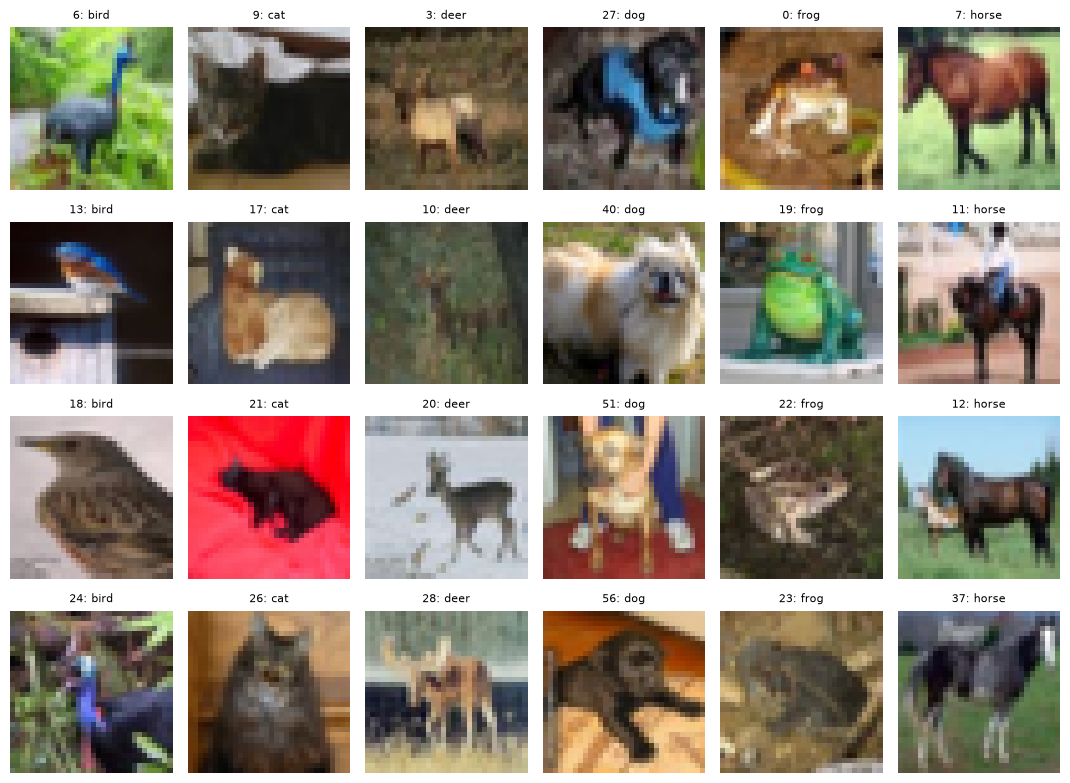

In [7]:
train_raw = CIFAR10(DATA_DIR, train=True, download=True)
targets = torch.tensor(train_raw.targets)
class_indices = {name: torch.nonzero(targets == train_raw.class_to_idx[name]).squeeze(1) for name in ANIMAL_CLASSES}
animal_indices = torch.cat(list(class_indices.values())).sort().values
class_counts = pd.Series({name: len(indices) for name, indices in class_indices.items()})

print(f"Train: {len(train_raw)} | image: {train_raw.data.shape[1:]} | dtype: {train_raw.data.dtype}")
print(f"Animals: {len(animal_indices)} of {len(train_raw)} | per class: from {class_counts.min()} to {class_counts.max()}")
print(", ".join(ANIMAL_CLASSES))

shown = [int(class_indices[name][row]) for row in range(SAMPLES_PER_CLASS) for name in ANIMAL_CLASSES]
examples = torch.from_numpy(train_raw.data[shown]).permute(0, 3, 1, 2).float() / 255
titles = [f"{index}: {train_raw.classes[train_raw.targets[index]]}" for index in shown]
saver.save(plot_image_grid(examples, titles, ncols=len(ANIMAL_CLASSES)), "samples");

x0: horse | shape: (1, 3, 32, 32) (batch, channels, height, width) | dtype: torch.float32
Range: [-0.929, 0.945]


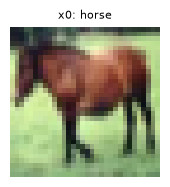

In [8]:
image_class = train_raw.classes[train_raw.targets[IMAGE_INDEX]]
if image_class not in ANIMAL_CLASSES:
    raise ValueError(f"IMAGE_INDEX must point to one of {ANIMAL_CLASSES}, got {IMAGE_INDEX} ({image_class})")


def to_model_range(data: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(data).permute(0, 3, 1, 2).float() / 127.5 - 1


def to_display(x: torch.Tensor) -> torch.Tensor:
    return (x + 1) / 2


x0 = to_model_range(train_raw.data[IMAGE_INDEX : IMAGE_INDEX + 1])

print(f"x0: {image_class} | shape: {tuple(x0.shape)} (batch, channels, height, width) | dtype: {x0.dtype}")
print(f"Range: [{x0.min().item():.3f}, {x0.max().item():.3f}]")
saver.save(plot_image_grid(to_display(x0), [f"x0: {image_class}"]), "x0");

alpha_bar[500]: cumprod 0.077797 | product of alphas 0.077797
beta_t: from 0.0001 to 0.0200
alpha_bar_t: from 0.9999 to 4.04e-05


,beta_t,alpha_t,alpha_bar_t
t,,,
100,0.002092,0.997908,0.895141
250,0.005080,0.994920,0.521423
500,0.010060,0.989940,0.077797
750,0.015040,0.984960,0.003300
999,0.020000,0.980000,0.000040


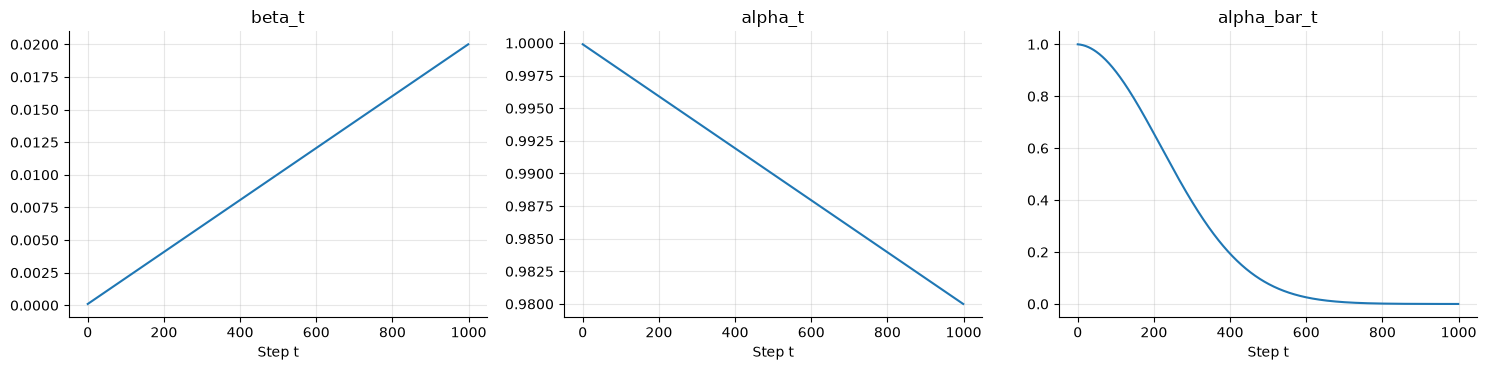

In [9]:
linear = NoiseSchedule(STEPS, LinearSchedule(BETA_START, BETA_END))
steps_axis = np.arange(STEPS)

direct_product = torch.prod(linear.alphas[: MANUAL_STEP + 1]).item()
print(f"alpha_bar[{MANUAL_STEP}]: cumprod {linear.alpha_bars[MANUAL_STEP].item():.6f} | product of alphas {direct_product:.6f}")
print(f"beta_t: from {linear.betas[0].item():.4f} to {linear.betas[-1].item():.4f}")
print(f"alpha_bar_t: from {linear.alpha_bars[0].item():.4f} to {linear.alpha_bars[-1].item():.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, values, title in zip(axes, [linear.betas, linear.alphas, linear.alpha_bars], ["beta_t", "alpha_t", "alpha_bar_t"]):
    ax.plot(steps_axis, values.numpy())
    ax.set_xlabel("Step t")
    ax.set_title(title)
fig.tight_layout()
saver.save(fig, "linear_schedule")

pd.DataFrame(
    {
        "beta_t": linear.betas[list(SHOWN_STEPS)].numpy(),
        "alpha_t": linear.alphas[list(SHOWN_STEPS)].numpy(),
        "alpha_bar_t": linear.alpha_bars[list(SHOWN_STEPS)].numpy(),
    },
    index=pd.Index(SHOWN_STEPS, name="t"),
).round(6)

In [10]:
eps = torch.randn(x0.shape, generator=torch.Generator().manual_seed(SEED))

beta = linear.betas[MANUAL_STEP].item()
alpha = linear.alphas[MANUAL_STEP].item()
alpha_bar = linear.alpha_bars[MANUAL_STEP].item()
x0_pixel = x0[0, *MANUAL_PIXEL].item()
eps_pixel = eps[0, *MANUAL_PIXEL].item()

signal = np.sqrt(alpha_bar) * x0_pixel
noise = np.sqrt(1 - alpha_bar) * eps_pixel
x_t_pixel = signal + noise
library_pixel = linear.add_noise(x0, torch.tensor([MANUAL_STEP]), eps)[0, *MANUAL_PIXEL].item()

print(f"t = {MANUAL_STEP}: beta = {beta:.6f} | alpha = 1 - beta = {alpha:.6f} | alpha_bar = {alpha_bar:.6f}")
print(f"Pixel (channel, row, column) = {MANUAL_PIXEL}: x0 = {x0_pixel:.4f} | eps = {eps_pixel:.4f}")
print(f"Signal part: sqrt({alpha_bar:.4f}) * {x0_pixel:.4f} = {signal:.4f}")
print(f"Noise part:  sqrt(1 - {alpha_bar:.4f}) * {eps_pixel:.4f} = {noise:.4f}")
print(f"x_t = {signal:.4f} + {noise:.4f} = {x_t_pixel:.4f} | add_noise: {library_pixel:.4f}")

pixel_alpha_bars = linear.alpha_bars[list(SHOWN_STEPS)].numpy()
pixel_table = pd.DataFrame(
    {
        "alpha_bar_t": pixel_alpha_bars,
        "signal part": np.sqrt(pixel_alpha_bars) * x0_pixel,
        "noise part": np.sqrt(1 - pixel_alpha_bars) * eps_pixel,
    },
    index=pd.Index(SHOWN_STEPS, name="t"),
)
pixel_table["x_t"] = pixel_table["signal part"] + pixel_table["noise part"]
pixel_table.round(5)

t = 500: beta = 0.010060 | alpha = 1 - beta = 0.989940 | alpha_bar = 0.077797
Pixel (channel, row, column) = (0, 16, 16): x0 = 0.1686 | eps = 1.3439
Signal part: sqrt(0.0778) * 0.1686 = 0.0470
Noise part:  sqrt(1 - 0.0778) * 1.3439 = 1.2905
x_t = 0.0470 + 1.2905 = 1.3376 | add_noise: 1.3376


,alpha_bar_t,signal part,noise part,x_t
t,,,,
100,0.89514,0.15954,0.43516,0.59471
250,0.52142,0.12177,0.92967,1.05143
500,0.07780,0.04703,1.29052,1.33755
750,0.00330,0.00969,1.34163,1.35132
999,0.00004,0.00107,1.34382,1.34490


Row: (6, 3, 32, 32) | range: [-3.84, 3.51]


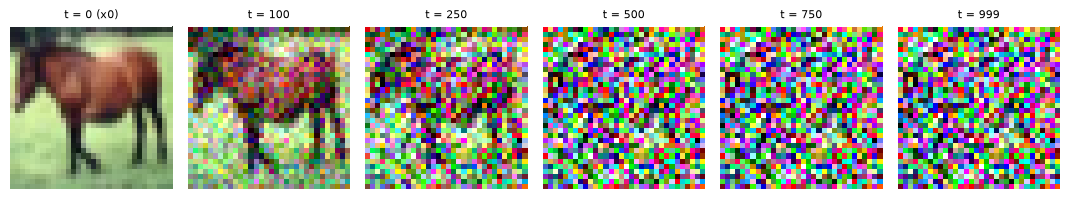

In [11]:
def noisy_row(schedule: NoiseSchedule, image: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
    images = image.expand(len(SHOWN_STEPS), -1, -1, -1)
    noisy = schedule.add_noise(images, torch.tensor(SHOWN_STEPS), noise.expand_as(images))
    return torch.cat([image, noisy])


linear_row = noisy_row(linear, x0, eps)
row_titles = ["t = 0 (x0)"] + [f"t = {step}" for step in SHOWN_STEPS]

print(f"Row: {tuple(linear_row.shape)} | range: [{linear_row.min().item():.2f}, {linear_row.max().item():.2f}]")
saver.save(plot_image_grid(to_display(linear_row), row_titles, ncols=len(row_titles)), "forward_linear");

Noise dominates from t = 259
x0:  mean -0.046 | std 0.466
x_T: mean 0.005 | std 0.994
x_T correlation: with x0 -0.0152 | with eps 1.0000


,alpha_bar_t,sqrt(alpha_bar_t),sqrt(1 - alpha_bar_t),dominates
t,,,,
100,0.89514,0.94612,0.32382,image
250,0.52142,0.72210,0.69179,image
500,0.07780,0.27892,0.96031,noise
750,0.00330,0.05745,0.99835,noise
999,0.00004,0.00635,0.99998,noise


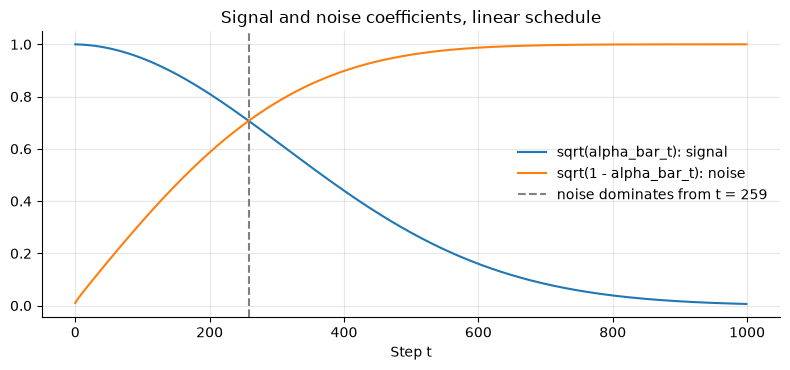

In [12]:
def correlation(x: torch.Tensor, reference: torch.Tensor) -> torch.Tensor:
    x = x.flatten(1) - x.flatten(1).mean(dim=1, keepdim=True)
    reference = reference.flatten(1) - reference.flatten(1).mean(dim=1, keepdim=True)
    return (x * reference).sum(dim=1) / (x.norm(dim=1) * reference.norm(dim=1))


signal_coef = torch.sqrt(linear.alpha_bars)
noise_coef = torch.sqrt(1 - linear.alpha_bars)
crossing = int((signal_coef < noise_coef).nonzero()[0])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(steps_axis, signal_coef.numpy(), label="sqrt(alpha_bar_t): signal")
ax.plot(steps_axis, noise_coef.numpy(), label="sqrt(1 - alpha_bar_t): noise")
ax.axvline(crossing, color="gray", linestyle="--", label=f"noise dominates from t = {crossing}")
ax.set_xlabel("Step t")
ax.set_title("Signal and noise coefficients, linear schedule")
ax.legend()
fig.tight_layout()
saver.save(fig, "signal_vs_noise")

x_last = linear.add_noise(x0, torch.tensor([STEPS - 1]), eps)
print(f"Noise dominates from t = {crossing}")
print(f"x0:  mean {x0.mean().item():.3f} | std {x0.std().item():.3f}")
print(f"x_T: mean {x_last.mean().item():.3f} | std {x_last.std().item():.3f}")
print(f"x_T correlation: with x0 {correlation(x_last, x0).item():.4f} | with eps {correlation(x_last, eps).item():.4f}")

shown_signal = signal_coef[list(SHOWN_STEPS)].numpy()
shown_noise = noise_coef[list(SHOWN_STEPS)].numpy()
pd.DataFrame(
    {
        "alpha_bar_t": linear.alpha_bars[list(SHOWN_STEPS)].numpy(),
        "sqrt(alpha_bar_t)": shown_signal,
        "sqrt(1 - alpha_bar_t)": shown_noise,
        "dominates": np.where(shown_signal > shown_noise, "image", "noise"),
    },
    index=pd.Index(SHOWN_STEPS, name="t"),
).round(5)

,linear,cosine
t,,
100,0.89514,0.97158
250,0.52142,0.84589
500,0.07780,0.49229
750,0.00330,0.14318
999,0.00004,0.00000


,linear,cosine
first t with alpha_bar < 0.5,259,496
first t with alpha_bar < 0.01,673,935


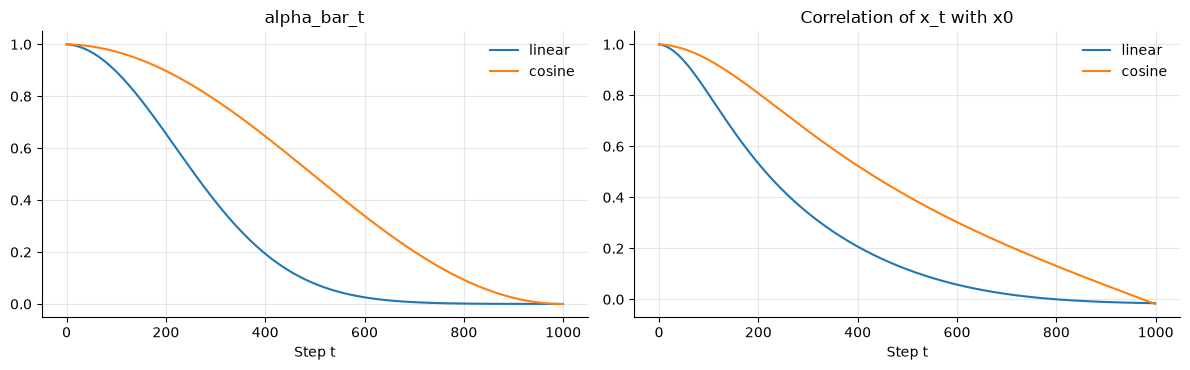

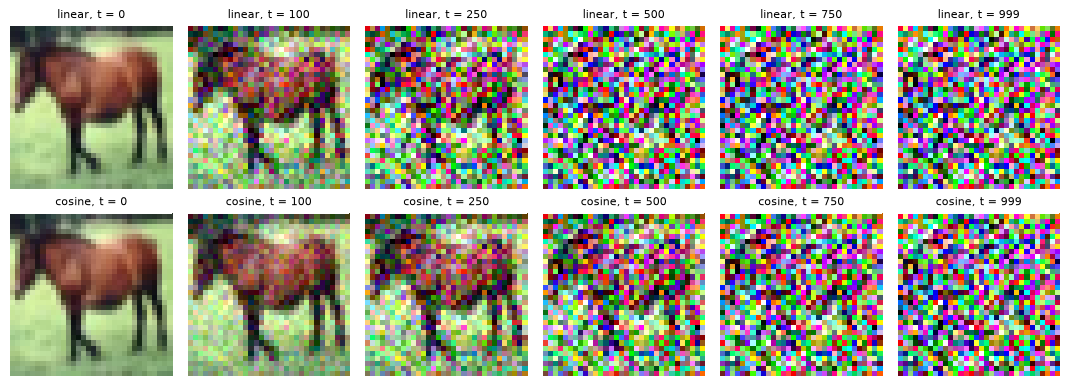

In [13]:
cosine = NoiseSchedule(STEPS, CosineSchedule())
schedules = {"linear": linear, "cosine": cosine}

all_images = x0.expand(STEPS, -1, -1, -1)
all_noise = eps.expand_as(all_images)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, schedule in schedules.items():
    noisy = schedule.add_noise(all_images, torch.arange(STEPS), all_noise)
    axes[0].plot(steps_axis, schedule.alpha_bars.numpy(), label=name)
    axes[1].plot(steps_axis, correlation(noisy, x0).numpy(), label=name)
for ax, title in zip(axes, ["alpha_bar_t", "Correlation of x_t with x0"]):
    ax.set_xlabel("Step t")
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
saver.save(fig, "linear_vs_cosine")

rows = torch.cat([noisy_row(schedule, x0, eps) for schedule in schedules.values()])
titles = [f"{name}, t = {step}" for name in schedules for step in (0, *SHOWN_STEPS)]
saver.save(plot_image_grid(to_display(rows), titles, ncols=len(SHOWN_STEPS) + 1), "forward_linear_vs_cosine")

display(pd.DataFrame(
    {name: schedule.alpha_bars[list(SHOWN_STEPS)].numpy() for name, schedule in schedules.items()},
    index=pd.Index(SHOWN_STEPS, name="t"),
).round(5))

pd.DataFrame({
    name: {
        f"first t with alpha_bar < {threshold}": int((schedule.alpha_bars < threshold).nonzero()[0])
        for threshold in ALPHA_BAR_THRESHOLDS
    }
    for name, schedule in schedules.items()
})

linear                     cosine              
    mse(x_t, x0) corr(x_t, x0) mse(x_t, x0) corr(x_t, x0)
t                                                        
100       0.1045        0.8037       0.0281        0.9386
250       0.4927        0.4260       0.1541        0.7336
500       1.0361        0.1171       0.5244        0.4052
750       1.1946        0.0088       0.9403        0.1708
999       1.2203       -0.0152       1.2232       -0.0181

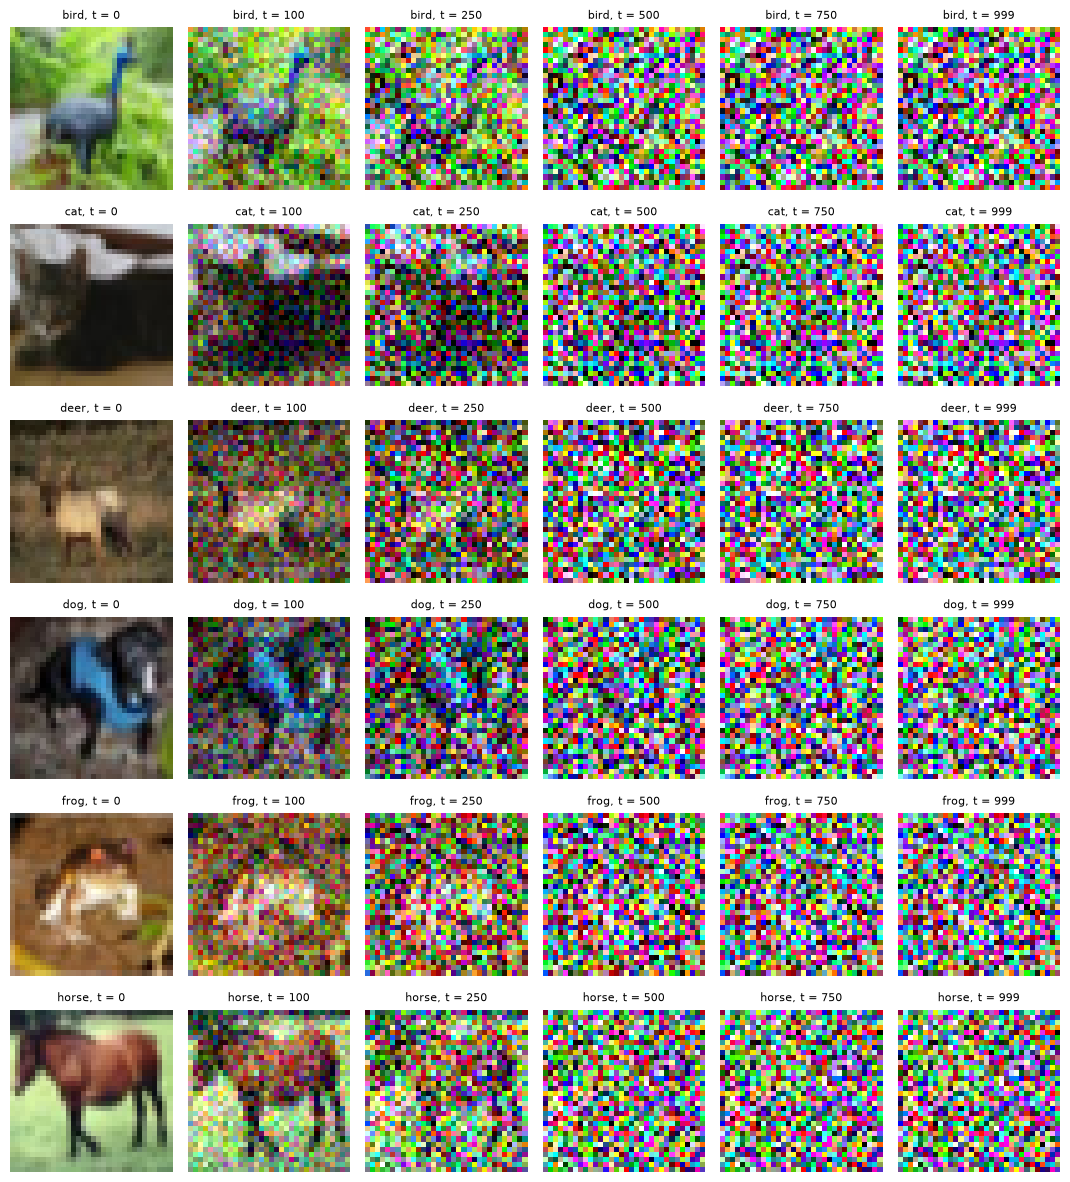

In [14]:
first_animals = [int(class_indices[name][0]) for name in ANIMAL_CLASSES]
animals = to_model_range(train_raw.data[first_animals])
animal_noise = torch.randn(animals.shape, generator=torch.Generator().manual_seed(SEED))
animal_rows = torch.cat([noisy_row(linear, animals[i : i + 1], animal_noise[i : i + 1]) for i in range(len(animals))])
animal_titles = [f"{name}, t = {step}" for name in ANIMAL_CLASSES for step in (0, *SHOWN_STEPS)]
saver.save(plot_image_grid(to_display(animal_rows), animal_titles, ncols=len(SHOWN_STEPS) + 1), "forward_animals")

recognizability = {}
for name, schedule in schedules.items():
    noisy = noisy_row(schedule, x0, eps)[1:]
    recognizability[name] = pd.DataFrame(
        {
            "mse(x_t, x0)": ((noisy - x0) ** 2).mean(dim=(1, 2, 3)).numpy(),
            "corr(x_t, x0)": correlation(noisy, x0).numpy(),
        },
        index=pd.Index(SHOWN_STEPS, name="t"),
    )

pd.concat(recognizability, axis=1).round(4)